# Problem 2: Transformer from Scratch

This notebook implements a Transformer architecture from scratch using tensor operations and evaluates it on two sequence-learning tasks.

The implementation includes:

- Scaled Dot-Product Attention
- Multi-Head Attention
- Sinusoidal Positional Encoding
- Transformer Encoder Block

These components are applied to:

1. Human Activity Recognition (HAR)
2. Character-Level Language Modeling using Tiny Shakespeare

The experiments evaluate predictive performance, parameter efficiency, computational cost and the contribution of individual Transformer design choices.

The instructor clarification allows the variants table to be ignored.

The following configuration was used throughout Problem 2:

- Model width (d): 128
- Model seeds: 42, 123, 999
- Number of attention heads: 4
- Language model layers: 4
- Context length: 128

The same three seeds used in Problem 1 were reused here to ensure consistency across experiments.

In [4]:
# Chosen width: divisible by 1, 4 and 8 heads, as required by the clarification.
MODEL_WIDTH = 128
MODEL_SEEDS = (42,123,999)
NUM_HEADS_MAIN = 4
NUM_LAYERS_LM = 4
CONTEXT_LENGTH = 128

assert MODEL_WIDTH % 8 == 0
assert MODEL_WIDTH % NUM_HEADS_MAIN == 0
assert len(MODEL_SEEDS) == 3 and len(set(MODEL_SEEDS)) == 3

## 2.1 Scaled Dot-Product Attention

Scaled Dot-Product Attention forms the core computation used by Transformer architectures.

Given query (Q), key (K) and value (V) matrices, attention scores are computed using:

Attention(Q,K,V) = Softmax(QKᵀ / √dₖ)V

A custom implementation was developed using tensor operations without relying on PyTorch Transformer modules.

The implementation supports optional attention masking and was validated against PyTorch's reference implementation using randomized test cases and a manually verified three-token example.

In [5]:
import math
import random
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RESULT_COLUMNS = [
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats",
    "bits_per_char", "notes",
]


def find_project_root():
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "problem2").is_dir() and (base / "results.csv").is_file():
            return base
        for child in base.glob("*_DNN_Assignment"):
            if (child / "problem2").is_dir() and (child / "results.csv").is_file():
                return child
    raise FileNotFoundError("Could not locate the assignment project root.")

try:
    PROJECT_ROOT = find_project_root()

except FileNotFoundError:

    candidate = Path.cwd() / "2026AK05029_DNN_Assignment"

    if candidate.exists():
        PROJECT_ROOT = candidate
    else:
        PROJECT_ROOT = Path.cwd()

    print(
        f"Using fallback project root: {PROJECT_ROOT}"
    )

FIGURE_DIR = PROJECT_ROOT / "problem2" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def save_result(row):
    result_path = PROJECT_ROOT / "results.csv"
    new_row = {column: row.get(column, "") for column in RESULT_COLUMNS}
    if result_path.exists() and result_path.stat().st_size:
        table = pd.read_csv(result_path).reindex(columns=RESULT_COLUMNS)
    else:
        table = pd.DataFrame(columns=RESULT_COLUMNS)
    key_columns = ["problem", "model", "seed", "seq_len"]
    if not table.empty:
        same_run = np.ones(len(table), dtype=bool)
        for column in key_columns:
            same_run &= table[column].astype(str).eq(str(new_row[column])).to_numpy()
        table = table.loc[~same_run]
    table = pd.concat([table, pd.DataFrame([new_row])], ignore_index=True)
    table.to_csv(result_path, index=False, columns=RESULT_COLUMNS)



Using fallback project root: /content


### Manual Attention Example

A three-token example is used to verify the correctness of the custom attention implementation.

For the first query vector:

Q = [1,0]

The unscaled attention scores are:

[1,0,1]

After scaling by √2 and applying Softmax, the resulting attention weights are multiplied with V to obtain the final attention output.

The manually calculated result is compared with the implementation below.

In [6]:
def scaled_dot_product_attention(q, k, v, mask=None):
    """
    q : (..., Tq, Dk)
    k : (..., Tk, Dk)
    v : (..., Tk, Dv)

    returns:
        output  -> (..., Tq, Dv)
        weights -> (..., Tq, Tk)
    """

    d_k = q.shape[-1]

    scores = torch.matmul(
        q,
        k.transpose(-2, -1)
    ) / math.sqrt(d_k)

    if mask is not None:

        while mask.dim() < scores.dim():
            mask = mask.unsqueeze(0)

        scores = scores.masked_fill(
            ~mask,
            float("-inf")
        )

    weights = torch.softmax(
        scores,
        dim=-1
    )

    output = torch.matmul(
        weights,
        v
    )

    return output, weights

def scaled_dot_attention_contract(q, k, v, mask=None):
    """Check a student function with contract (output, weights) = f(Q,K,V,mask).

    Expected shapes are Q=(B,...,Tq,Dk), K=(B,...,Tk,Dk),
    V=(B,...,Tk,Dv), weights=(B,...,Tq,Tk), output=(B,...,Tq,Dv).
    Boolean mask semantics: True means the query/key pair is allowed.
    """
    if "scaled_dot_product_attention" not in globals():
        print("Add your scaled_dot_product_attention function, then rerun these tests.")
        return None
    output, weights = scaled_dot_product_attention(q, k, v, mask)
    expected = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
    assert output.shape == expected.shape
    assert weights.shape == q.shape[:-1] + (k.shape[-2],)
    torch.testing.assert_close(weights.sum(dim=-1), torch.ones_like(weights.sum(dim=-1)), atol=1e-6, rtol=0)
    torch.testing.assert_close(output, expected, atol=1e-5, rtol=1e-5)

    token_count = q.shape[-2]
    causal_mask = torch.ones(token_count, token_count, dtype=torch.bool, device=q.device).tril()
    _, causal_weights = scaled_dot_product_attention(q, k, v, causal_mask)
    future = torch.triu(torch.ones_like(causal_weights, dtype=torch.bool), diagonal=1)
    assert torch.count_nonzero(causal_weights.masked_select(future)) == 0
    return float((output - expected).abs().max().item())


# Small 3-token example: compute logits QK^T/sqrt(2), row-softmax weights,
# then multiply by V. For query 1 the unscaled logits are [1, 0, 1].
HAND_Q = torch.tensor([[[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]])
HAND_K = torch.tensor([[[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]])
HAND_V = torch.tensor([[[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]])
HAND_FIRST_ROW_WEIGHTS = torch.softmax(torch.tensor([1.0, 0.0, 1.0]) / math.sqrt(2.0), dim=0)
HAND_FIRST_ROW_OUTPUT = HAND_FIRST_ROW_WEIGHTS @ HAND_V[0]
print("Hand example first-token weights:", HAND_FIRST_ROW_WEIGHTS.tolist())
print("Hand example first-token output:", HAND_FIRST_ROW_OUTPUT.tolist())

# Randomized oracle tests are ready to run after you define the function above.
if "scaled_dot_product_attention" in globals():
    _q = torch.randn(2, 4, 5, 8)
    _k = torch.randn(2, 4, 5, 8)
    _v = torch.randn(2, 4, 5, 6)
    max_difference = scaled_dot_attention_contract(_q, _k, _v)
    print(f"Scaled-Dot-Product Attention maximum absolute difference: {max_difference:.3g}")
else:
    print("2.1 tests are prepared; the required student attention function is not defined yet.")

Hand example first-token weights: [0.40111207962036133, 0.19777581095695496, 0.40111207962036133]
Hand example first-token output: [0.8022241592407227, 0.5988879203796387]
Scaled-Dot-Product Attention maximum absolute difference: 2.98e-07


In [7]:
def verify_hand_attention_example():
    """Compare your attention function with the printed 3-token calculation."""
    if "scaled_dot_product_attention" not in globals():
        print("Define your scaled_dot_product_attention function before this check.")
        return None
    output, weights = scaled_dot_product_attention(HAND_Q, HAND_K, HAND_V, None)
    torch.testing.assert_close(weights[0, 0], HAND_FIRST_ROW_WEIGHTS, atol=1e-6, rtol=0)
    torch.testing.assert_close(output[0, 0], HAND_FIRST_ROW_OUTPUT, atol=1e-6, rtol=0)
    return output, weights


if "scaled_dot_product_attention" in globals():
    verify_hand_attention_example()

## 2.2 Multi-Head Attention and Encoder Block

Multi-Head Attention extends scaled dot-product attention by allowing the model to attend to information from multiple representation subspaces simultaneously.

The implementation contains:

- Query projection (WQ)
- Key projection (WK)
- Value projection (WV)
- Output projection (WO)

The projected representations are divided across multiple attention heads. Attention is evaluated independently within each head before the outputs are concatenated and projected back to the model dimension.

A pre-LayerNorm Transformer Encoder Block was implemented using:

- Multi-Head Attention
- Residual Connections
- Layer Normalization
- Feed-Forward Network
- Dropout

For the assignment configuration:

- Model width (d) = 128
- Feed-forward width (dff) = 512

The matrix-weight contribution is:

4 × d² + 2 × d × dff

= 4 × 128² + 2 × 128 × 512

= 196,608

The remaining parameters arise from linear-layer biases and LayerNorm parameters.

In [8]:
def sinusoidal_position_encoding(length, width, device=None, dtype=None):
    """Return the standard (1, length, width) sinusoidal position table."""
    positions = torch.arange(length, device=device, dtype=torch.float32).unsqueeze(1)
    dimensions = torch.arange(width, device=device, dtype=torch.float32).unsqueeze(0)
    rates = torch.exp(-math.log(10_000.0) * (2 * torch.floor(dimensions / 2)) / width)
    angles = positions * rates
    encoding = torch.where(dimensions.remainder(2) == 0, torch.sin(angles), torch.cos(angles))
    return encoding.unsqueeze(0).to(dtype=dtype or torch.float32)


def encoder_matrix_weight_count(width, feed_forward_width=None):
    feed_forward_width = feed_forward_width or 4 * width
    return 4 * width * width + 2 * width * feed_forward_width

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)
        self.W_O = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None, return_attention=False):
        batch_size, sequence_length, width = x.shape
        q = self.W_Q(x).view(
            batch_size, sequence_length, self.num_heads, self.head_dim
        ).transpose(1, 2)
        k = self.W_K(x).view(
            batch_size, sequence_length, self.num_heads, self.head_dim
        ).transpose(1, 2)
        v = self.W_V(x).view(
            batch_size, sequence_length, self.num_heads, self.head_dim
        ).transpose(1, 2)
        output, weights = scaled_dot_product_attention(q, k, v, mask)
        output = output.transpose(1, 2).contiguous().view(
            batch_size, sequence_length, width
        )
        output = self.W_O(output)
        if return_attention:
            return output, weights
        return output


class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.attention = MultiHeadAttention(d_model, num_heads, dropout)
        self.dropout = nn.Dropout(dropout)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(4 * d_model, d_model),
        )

    def forward(self, x, mask=None, return_attention=False):
        normed = self.norm1(x)
        if return_attention:
            attn_out, weights = self.attention(
                normed, mask=mask, return_attention=True
            )
        else:
            attn_out = self.attention(normed, mask=mask)
        x = x + self.dropout(attn_out)
        x = x + self.dropout(self.feed_forward(self.norm2(x)))
        if return_attention:
            return x, weights
        return x


def validate_student_encoder_block(block_class, width=MODEL_WIDTH, heads=NUM_HEADS_MAIN):
    """Check output shape, causal weights, and parameter-count reconciliation."""
    block = block_class(d_model=width, num_heads=heads, dropout=0.0)
    sample = torch.randn(2, 7, width)
    output = block(sample)
    if isinstance(output, tuple):
        output = output[0]
    assert output.shape == sample.shape

    causal_mask = torch.ones(7, 7, dtype=torch.bool).tril()
    masked_output, attention_weights = block(
        sample, mask=causal_mask, return_attention=True
    )
    assert masked_output.shape == sample.shape
    assert attention_weights.shape[-2:] == (7, 7)
    future = torch.triu(torch.ones_like(attention_weights, dtype=torch.bool), diagonal=1)
    assert torch.count_nonzero(attention_weights.masked_select(future)) == 0

    actual_parameters = sum(parameter.numel() for parameter in block.parameters())
    matrix_weights = encoder_matrix_weight_count(width)
    print(
        f"EncoderBlock params={actual_parameters}; matrix weights={matrix_weights}; "
        f"biases/norm parameters={actual_parameters - matrix_weights}"
    )
    return actual_parameters


assert encoder_matrix_weight_count(128, 512) == 196_608
assert sinusoidal_position_encoding(5, MODEL_WIDTH).shape == (1, 5, MODEL_WIDTH)
if "EncoderBlock" in globals() and "MultiHeadAttention" in globals():
    validate_student_encoder_block(EncoderBlock)
else:
    print("EncoderBlock test is deferred until MultiHeadAttention is defined below.")


EncoderBlock params=198272; matrix weights=196608; biases/norm parameters=1664


In [9]:
def validate_student_multihead_attention(attention_class, width=MODEL_WIDTH, heads=NUM_HEADS_MAIN):
    """Check output shape, normalized weights, and causal masking."""
    module = attention_class(d_model=width, num_heads=heads, dropout=0.0)
    values = torch.randn(2, 6, width)
    output, weights = module(values, return_attention=True)
    assert output.shape == values.shape
    assert weights.shape == (2, heads, 6, 6)
    torch.testing.assert_close(
        weights.sum(dim=-1), torch.ones_like(weights.sum(dim=-1)), atol=1e-6, rtol=0
    )
    allowed = torch.ones(6, 6, dtype=torch.bool).tril()
    masked_output, masked_weights = module(values, mask=allowed, return_attention=True)
    assert masked_output.shape == values.shape
    future = torch.triu(torch.ones_like(masked_weights, dtype=torch.bool), diagonal=1)
    assert torch.count_nonzero(masked_weights.masked_select(future)) == 0
    return sum(parameter.numel() for parameter in module.parameters())


if "MultiHeadAttention" in globals():
    mha_parameters = validate_student_multihead_attention(MultiHeadAttention)
    print(f"MultiHeadAttention checks passed; parameters={mha_parameters}.")

if "EncoderBlock" in globals():
    encoder_parameters = validate_student_encoder_block(EncoderBlock)
    print(f"EncoderBlock checks passed; parameters={encoder_parameters}.")

MultiHeadAttention checks passed; parameters=66048.
EncoderBlock params=198272; matrix weights=196608; biases/norm parameters=1664
EncoderBlock checks passed; parameters=198272.


## 2.3 Task A: Human Activity Recognition Using a Transformer Encoder

The Human Activity Recognition dataset from Problem 1 was reused to evaluate a Transformer-based sequence classifier.

Each sensor time step was projected into the model embedding space and augmented with a learnable CLS token used for sequence-level classification.

Three positional-information settings were evaluated:

- No positional encoding
- Sinusoidal positional encoding
- Learned positional encoding

The same subject-wise validation split, normalization strategy and evaluation metrics used in Problem 1 were retained to ensure a fair comparison between recurrent architectures and Transformer-based models.

Model performance is reported using:

- Test Accuracy
- Macro-F1 Score
- Parameter Count
- Average Time per Epoch

Results are compared against the best recurrent architecture from Problem 1.

In [10]:
import copy
import zipfile

from sklearn.metrics import accuracy_score, f1_score

HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_CACHE = PROJECT_ROOT.parent / "har_data"
HAR_CHANNELS = (
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
)
ACTIVITY_NAMES = ("Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying")


def ensure_har_dataset():
    HAR_CACHE.mkdir(parents=True, exist_ok=True)
    extracted = list(HAR_CACHE.rglob("train/Inertial Signals"))
    if extracted:
        return extracted[0].parents[1]
    archive_path = HAR_CACHE / "har.zip"
    if not archive_path.exists():
        urllib.request.urlretrieve(HAR_URL, archive_path)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(HAR_CACHE)
    for nested in HAR_CACHE.rglob("UCI HAR Dataset.zip"):
        with zipfile.ZipFile(nested) as archive:
            archive.extractall(nested.parent)
    extracted = list(HAR_CACHE.rglob("train/Inertial Signals"))
    if not extracted:
        raise FileNotFoundError("Could not find extracted UCI HAR train signals.")
    return extracted[0].parents[1]


HAR_ROOT = ensure_har_dataset()


def load_har_for_transformer(seed):
    data = {}
    for split in ("train", "test"):
        signals_dir = HAR_ROOT / split / "Inertial Signals"
        channels = [
            np.loadtxt(signals_dir / f"{name}_{split}.txt", dtype=np.float32)
            for name in HAR_CHANNELS
        ]
        features = np.stack(channels, axis=-1)
        labels = np.loadtxt(HAR_ROOT / split / f"y_{split}.txt", dtype=np.int64) - 1
        subjects = np.loadtxt(HAR_ROOT / split / f"subject_{split}.txt", dtype=np.int64)
        data[split] = (features, labels, subjects)

    train_x, train_y, train_subjects = data["train"]
    test_x, test_y, _ = data["test"]
    validation_subjects = np.random.default_rng(seed).choice(
        np.unique(train_subjects), size=4, replace=False
    )
    validation_mask = np.isin(train_subjects, validation_subjects)
    training_mask = ~validation_mask
    mean = train_x[training_mask].mean(axis=(0, 1), keepdims=True)
    std = train_x[training_mask].std(axis=(0, 1), keepdims=True)
    std[std == 0] = 1.0
    return {
        "train_x": (train_x[training_mask] - mean) / std,
        "train_y": train_y[training_mask],
        "val_x": (train_x[validation_mask] - mean) / std,
        "val_y": train_y[validation_mask],
        "test_x": (test_x - mean) / std,
        "test_y": test_y,
    }


class StudentEncoderStack(nn.Module):
    """Stack the student's EncoderBlock; see the required 2.2 interface."""
    def __init__(self, width, heads, layers, dropout):
        super().__init__()
        if "EncoderBlock" not in globals():
            raise RuntimeError("Define your own EncoderBlock in section 2.2 first.")
        self.blocks = nn.ModuleList([
            EncoderBlock(d_model=width, num_heads=heads, dropout=dropout)
            for _ in range(layers)
        ])

    def forward(self, values, mask=None, return_attentions=False):
        attentions = []
        for block in self.blocks:
            if return_attentions:
                values, weights = block(values, mask=mask, return_attention=True)
                attentions.append(weights)
            else:
                values = block(values, mask=mask)
                if isinstance(values, tuple):
                    values = values[0]
        if return_attentions:
            return values, attentions
        return values


class HARTransformerClassifier(nn.Module):
    def __init__(self, position_mode, width=MODEL_WIDTH, heads=NUM_HEADS_MAIN,
                 layers=2, dropout=0.1):
        super().__init__()
        self.position_mode = position_mode
        self.input_projection = nn.Linear(9, width)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, width))
        self.learned_positions = (
            nn.Embedding(129, width) if position_mode == "learned" else None
        )
        self.encoder = StudentEncoderStack(width, heads, layers, dropout)
        self.classifier = nn.Linear(width, 6)

    def forward(self, inputs):
        batch_size = inputs.shape[0]
        values = self.input_projection(inputs)
        cls = self.cls_token.expand(batch_size, -1, -1)
        values = torch.cat((cls, values), dim=1)
        if self.position_mode == "sinusoidal":
            values = values + sinusoidal_position_encoding(
                values.shape[1], values.shape[2], values.device, values.dtype
            )
        elif self.position_mode == "learned":
            positions = torch.arange(values.shape[1], device=values.device)
            values = values + self.learned_positions(positions).unsqueeze(0)
        encoded = self.encoder(values)
        if isinstance(encoded, tuple):
            encoded = encoded[0]
        return self.classifier(encoded[:, 0])


def har_loader(data, split, batch_size=128):
    dataset = TensorDataset(
        torch.from_numpy(data[f"{split}_x"].astype(np.float32)),
        torch.from_numpy(data[f"{split}_y"].astype(np.int64)),
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=(split == "train"))


def evaluate_har_model(model, loader):
    model.eval()
    true_labels, predicted_labels = [], []
    with torch.no_grad():
        for values, labels in loader:
            logits = model(values.to(DEVICE))
            predicted_labels.extend(logits.argmax(dim=-1).cpu().tolist())
            true_labels.extend(labels.tolist())
    return (
        accuracy_score(true_labels, predicted_labels),
        f1_score(true_labels, predicted_labels, average="macro"),
    )


def run_har_transformer(epochs=10, heads=NUM_HEADS_MAIN):
    rows = []
    for seed in MODEL_SEEDS:
        data = load_har_for_transformer(seed)
        loaders = {split: har_loader(data, split) for split in ("train", "val", "test")}
        for position_mode in ("none", "sinusoidal", "learned"):
            set_all_seeds(seed)
            model = HARTransformerClassifier(position_mode, heads=heads).to(DEVICE)
            optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
            best_state, best_val_f1 = None, -1.0
            epoch_seconds = []
            for _ in range(epochs):
                model.train()
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                started = time.perf_counter()
                for values, labels in loaders["train"]:
                    values, labels = values.to(DEVICE), labels.to(DEVICE)
                    optimizer.zero_grad(set_to_none=True)
                    loss = F.cross_entropy(model(values), labels)
                    loss.backward()
                    optimizer.step()
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                epoch_seconds.append(time.perf_counter() - started)
                _, val_f1 = evaluate_har_model(model, loaders["val"])
                if val_f1 > best_val_f1:
                    best_val_f1 = val_f1
                    best_state = copy.deepcopy(model.state_dict())
            model.load_state_dict(best_state)
            test_acc, test_f1 = evaluate_har_model(model, loaders["test"])
            row = {
                "problem": "2_HAR", "model": f"Transformer_{position_mode}_heads{heads}",
                "seed": seed, "seq_len": 128, "test_acc": test_acc,
                "macro_f1": test_f1,
                "params": sum(parameter.numel() for parameter in model.parameters()),
                "sec_per_epoch": float(np.mean(epoch_seconds)),
                "notes": f"d={MODEL_WIDTH}; heads={heads}; layers=2; epochs={epochs}",
            }
            save_result(row)
            rows.append(row)
            print(f"{row['model']} seed={seed}: accuracy={test_acc:.4f}; macro-F1={test_f1:.4f}")
    results = pd.DataFrame(rows)
    summary = results.groupby("model").agg(
        accuracy_mean=("test_acc", "mean"), accuracy_std=("test_acc", "std"),
        macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
        params=("params", "first"), seconds_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)
    return summary


RUN_HAR_TRANSFORMER = True
if RUN_HAR_TRANSFORMER:
    har_transformer_summary = run_har_transformer()

/tmp/ipykernel_519/3915975217.py:73: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([table, pd.DataFrame([new_row])], ignore_index=True)


Transformer_none_heads4 seed=42: accuracy=0.8721; macro-F1=0.8716
Transformer_sinusoidal_heads4 seed=42: accuracy=0.8962; macro-F1=0.8959
Transformer_learned_heads4 seed=42: accuracy=0.8914; macro-F1=0.8907
Transformer_none_heads4 seed=123: accuracy=0.8683; macro-F1=0.8676
Transformer_sinusoidal_heads4 seed=123: accuracy=0.8524; macro-F1=0.8509
Transformer_learned_heads4 seed=123: accuracy=0.8622; macro-F1=0.8602
Transformer_none_heads4 seed=999: accuracy=0.8714; macro-F1=0.8678
Transformer_sinusoidal_heads4 seed=999: accuracy=0.8826; macro-F1=0.8815
Transformer_learned_heads4 seed=999: accuracy=0.8755; macro-F1=0.8749


,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,params,seconds_per_epoch
model,,,,,,
Transformer_learned_heads4,0.876371,0.014612,0.875241,0.015261,415238,1.520204
Transformer_none_heads4,0.870603,0.001988,0.868992,0.002260,398726,1.466878
Transformer_sinusoidal_heads4,0.877050,0.022407,0.876102,0.022953,398726,1.474984


In [11]:
def compare_har_with_recurrent_results(transformer_summary):
    """Display the saved Problem 1 baseline beside Transformer HAR results."""
    results = pd.read_csv(PROJECT_ROOT / "results.csv")
    recurrent = results[results["problem"] == "1_HAR"]
    if recurrent.empty:
        print("No Problem 1 HAR runs are saved yet; run that benchmark for the requested comparison.")
        display(transformer_summary)
        return None
    recurrent_summary = recurrent.groupby("model").agg(
        accuracy_mean=("test_acc", "mean"), accuracy_std=("test_acc", "std"),
        macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
        params=("params", "first"), seconds_per_epoch=("sec_per_epoch", "mean"),
    )
    recurrent_summary["family"] = "Recurrent"
    transformer = transformer_summary.copy()
    transformer["family"] = "Transformer"
    comparison = pd.concat([recurrent_summary, transformer], axis=0, sort=False)
    display(comparison)
    return comparison


# Call compare_har_with_recurrent_results(har_transformer_summary) after the HAR run.


## 2.4 Task B: character language model

Download Tiny Shakespeare and build its character list from the full text. It should contain 65 characters. Use the first 90% of the text for training and the last 10% for validation, keeping the original order.

Train a causal language model with context length `128`, `4` heads, `4` layers and your chosen width `d=128`. Report validation loss in nats and bits per character; calculate bits per character as loss divided by `ln(2)`. Generate and save one sample of exactly 500 characters at each temperature: `0.2`, `0.8` and `1.5`. Use top-k sampling and explain how the samples differ.

Loaded 1,115,394 characters and 65 unique characters.
seed=42 epoch=1/10: train=2.435 nats, val=2.169 nats
seed=42 epoch=2/10: train=1.998 nats, val=1.964 nats
seed=42 epoch=3/10: train=1.803 nats, val=1.841 nats
seed=42 epoch=4/10: train=1.694 nats, val=1.762 nats
seed=42 epoch=5/10: train=1.621 nats, val=1.733 nats
seed=42 epoch=6/10: train=1.571 nats, val=1.689 nats
seed=42 epoch=7/10: train=1.527 nats, val=1.660 nats
seed=42 epoch=8/10: train=1.504 nats, val=1.638 nats
seed=42 epoch=9/10: train=1.477 nats, val=1.620 nats
seed=42 epoch=10/10: train=1.456 nats, val=1.614 nats
seed=123 epoch=1/10: train=2.441 nats, val=2.198 nats
seed=123 epoch=2/10: train=2.018 nats, val=1.972 nats
seed=123 epoch=3/10: train=1.816 nats, val=1.863 nats
seed=123 epoch=4/10: train=1.701 nats, val=1.792 nats
seed=123 epoch=5/10: train=1.627 nats, val=1.737 nats
seed=123 epoch=6/10: train=1.575 nats, val=1.700 nats
seed=123 epoch=7/10: train=1.536 nats, val=1.672 nats
seed=123 epoch=8/10: train=1.505 nats

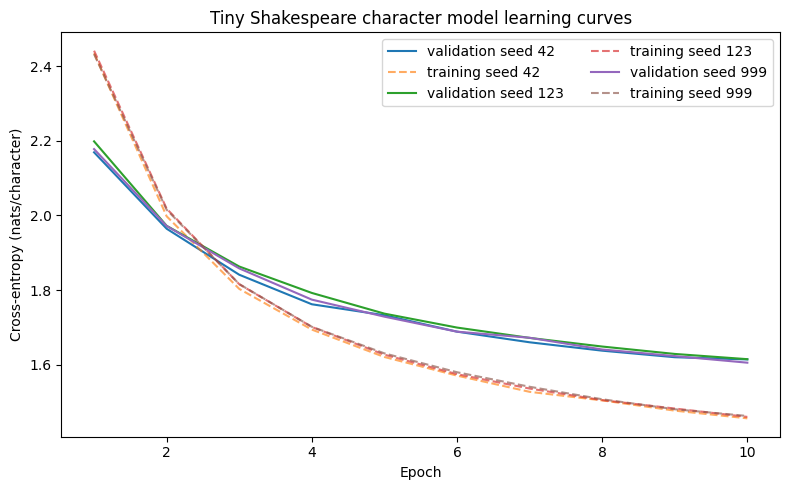

,val_loss_nats,bits_per_char,params,sec_per_epoch
seed,,,,
42,1.614196,2.328792,809793,7.168219
123,1.614887,2.329790,809793,7.068024
999,1.605479,2.316217,809793,7.116456


In [12]:
TINY_SHAKESPEARE_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
TINY_SHAKESPEARE_PATH = PROJECT_ROOT.parent / "tinyshakespeare.txt"
LM_BATCH_SIZE = 64
LM_CONTEXT_LENGTH = CONTEXT_LENGTH
LM_STEPS_PER_EPOCH = 200


def load_tiny_shakespeare():
    if not TINY_SHAKESPEARE_PATH.exists():
        text = urllib.request.urlopen(TINY_SHAKESPEARE_URL, timeout=60).read().decode("utf-8")
        TINY_SHAKESPEARE_PATH.write_text(text, encoding="utf-8")
    text = TINY_SHAKESPEARE_PATH.read_text(encoding="utf-8")
    vocabulary = sorted(set(text))
    if len(vocabulary) != 65:
        raise ValueError(f"Expected 65 unique characters; found {len(vocabulary)}")
    char_to_id = {character: index for index, character in enumerate(vocabulary)}
    encoded = torch.tensor([char_to_id[character] for character in text], dtype=torch.long)
    split_index = int(0.9 * len(encoded))
    return {
        "text": text,
        "vocabulary": vocabulary,
        "char_to_id": char_to_id,
        "id_to_char": {index: character for character, index in char_to_id.items()},
        "train": encoded[:split_index],
        "val": encoded[split_index:],
    }


class CharacterTransformerLM(nn.Module):
    def __init__(self, vocabulary_size, width=MODEL_WIDTH, heads=NUM_HEADS_MAIN,
                 layers=NUM_LAYERS_LM, dropout=0.1, causal=True):
        super().__init__()
        self.width = width
        self.causal = causal
        self.token_embedding = nn.Embedding(vocabulary_size, width)
        self.encoder = StudentEncoderStack(width, heads, layers, dropout)
        self.output_projection = nn.Linear(width, vocabulary_size)

    def forward(self, token_ids, return_attentions=False):
        sequence_length = token_ids.shape[1]
        values = self.token_embedding(token_ids)
        values = values + sinusoidal_position_encoding(
            sequence_length, self.width, values.device, values.dtype
        )
        mask = None
        if self.causal:
            mask = torch.ones(
                sequence_length, sequence_length, dtype=torch.bool, device=token_ids.device
            ).tril()
        if return_attentions:
            values, attentions = self.encoder(values, mask=mask, return_attentions=True)
            return self.output_projection(values), attentions
        values = self.encoder(values, mask=mask)
        return self.output_projection(values)


def sample_lm_batch(token_stream, batch_size=LM_BATCH_SIZE, context_length=LM_CONTEXT_LENGTH):
    starts = torch.randint(0, len(token_stream) - context_length - 1, (batch_size,))
    inputs = torch.stack([token_stream[start : start + context_length] for start in starts])
    targets = torch.stack([token_stream[start + 1 : start + context_length + 1] for start in starts])
    return inputs.to(DEVICE), targets.to(DEVICE)


@torch.no_grad()
def evaluate_language_model(model, token_stream, context_length=LM_CONTEXT_LENGTH):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for start in range(0, len(token_stream) - 1, context_length):
        input_chunk = token_stream[start : start + context_length]
        target_chunk = token_stream[start + 1 : start + context_length + 1]
        if len(input_chunk) != len(target_chunk) or len(input_chunk) == 0:
            continue
        logits = model(input_chunk.unsqueeze(0).to(DEVICE))
        loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), target_chunk.to(DEVICE))
        total_loss += loss.item() * len(target_chunk)
        total_tokens += len(target_chunk)
    return total_loss / total_tokens


def train_language_model(data, seed, epochs=10, steps_per_epoch=LM_STEPS_PER_EPOCH,
                         heads=NUM_HEADS_MAIN, causal=True):
    set_all_seeds(seed)
    model = CharacterTransformerLM(
        len(data["vocabulary"]), heads=heads, causal=causal
    ).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    train_history, val_history, epoch_seconds = [], [], []
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        for _ in range(steps_per_epoch):
            inputs, targets = sample_lm_batch(data["train"])
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running_loss += loss.item()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_seconds.append(time.perf_counter() - started)
        train_history.append(running_loss / steps_per_epoch)
        val_history.append(evaluate_language_model(model, data["val"]))
        print(
            f"seed={seed} epoch={epoch + 1}/{epochs}: "
            f"train={train_history[-1]:.3f} nats, val={val_history[-1]:.3f} nats"
        )
    return model, train_history, val_history, float(np.mean(epoch_seconds))


@torch.no_grad()
def generate_text(model, data, temperature, length=500, top_k=20, seed=MODEL_SEEDS[0]):
    set_all_seeds(seed)
    model.eval()
    prompt_id = data["char_to_id"].get("\n", 0)
    generated = torch.tensor([[prompt_id]], dtype=torch.long, device=DEVICE)
    for _ in range(length - 1):
        context = generated[:, -LM_CONTEXT_LENGTH:]
        logits = model(context)[:, -1, :] / temperature
        if top_k is not None:
            values, indices = torch.topk(logits, min(top_k, logits.shape[-1]), dim=-1)
            filtered = torch.full_like(logits, float("-inf"))
            filtered.scatter_(1, indices, values)
            logits = filtered
        next_id = torch.multinomial(torch.softmax(logits, dim=-1), num_samples=1)
        generated = torch.cat((generated, next_id), dim=1)
    return "".join(data["id_to_char"][int(index)] for index in generated[0].cpu())


def run_language_model(epochs=10, steps_per_epoch=LM_STEPS_PER_EPOCH):
    data = load_tiny_shakespeare()
    print(f"Loaded {len(data['text']):,} characters and {len(data['vocabulary'])} unique characters.")
    all_rows, histories, models = [], {}, {}
    for seed in MODEL_SEEDS:
        model, train_history, val_history, seconds = train_language_model(
            data, seed, epochs=epochs, steps_per_epoch=steps_per_epoch
        )
        models[seed] = model
        histories[seed] = (train_history, val_history)
        val_nats = evaluate_language_model(model, data["val"])
        row = {
            "problem": "2_language_model", "model": f"Transformer_d{MODEL_WIDTH}_h{NUM_HEADS_MAIN}_L{NUM_LAYERS_LM}",
            "seed": seed, "seq_len": LM_CONTEXT_LENGTH,
            "params": sum(parameter.numel() for parameter in model.parameters()),
            "sec_per_epoch": seconds, "val_loss_nats": val_nats,
            "bits_per_char": val_nats / math.log(2),
            "notes": f"d={MODEL_WIDTH}; heads={NUM_HEADS_MAIN}; layers={NUM_LAYERS_LM}; epochs={epochs}",
        }
        save_result(row)
        all_rows.append(row)

    figure, axis = plt.subplots(figsize=(8, 5))
    for seed, (train_history, val_history) in histories.items():
        axis.plot(np.arange(1, epochs + 1), val_history, label=f"validation seed {seed}")
        axis.plot(np.arange(1, epochs + 1), train_history, linestyle="--", alpha=0.65,
                  label=f"training seed {seed}")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Cross-entropy (nats/character)")
    axis.set_title("Tiny Shakespeare character model learning curves")
    axis.legend(ncol=2)
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "language_model_learning_curves.png", dpi=160)
    plt.show()
    plt.close(figure)

    sample_model = models[MODEL_SEEDS[0]]
    sample_sections = []
    for temperature in (0.2, 0.8, 1.5):
        sample = generate_text(sample_model, data, temperature, length=500, seed=MODEL_SEEDS[0])
        assert len(sample) == 500
        sample_sections.append(f"Temperature {temperature:.1f}\n{sample}")
    samples_path = PROJECT_ROOT / "problem2" / "generated_samples.txt"
    samples_path.write_text("\n\n".join(sample_sections) + "\n", encoding="utf-8")
    summary = pd.DataFrame(all_rows).set_index("seed")[["val_loss_nats", "bits_per_char", "params", "sec_per_epoch"]]
    display(summary)
    return data, models, summary


RUN_LANGUAGE_MODEL = True
if RUN_LANGUAGE_MODEL:
    tiny_data, language_models, language_model_summary = run_language_model()

In [13]:
# Data-only smoke check; model training waits for your custom EncoderBlock.
tiny_data = load_tiny_shakespeare()
_smoke_inputs, _smoke_targets = sample_lm_batch(tiny_data["train"], batch_size=4)
assert len(tiny_data["vocabulary"]) == 65
assert _smoke_inputs.shape == _smoke_targets.shape == (4, CONTEXT_LENGTH)
assert len(tiny_data["train"]) + len(tiny_data["val"]) == len(tiny_data["text"])
print(
    f"Tiny Shakespeare ready: {len(tiny_data['text']):,} chars, "
    f"train={len(tiny_data['train']):,}, validation={len(tiny_data['val']):,}."
)
del _smoke_inputs, _smoke_targets


Tiny Shakespeare ready: 1,115,394 chars, train=1,003,854, validation=111,540.


## 2.5 Attention Analysis and Ablation Studies

Additional experiments were performed to investigate the behavior of Transformer attention mechanisms and to evaluate the contribution of specific architectural components.

The following studies were conducted:

### Attention Heatmaps
Attention patterns from two heads were visualized to understand which positions receive the strongest attention.

### Head-Count Ablation
Models with 1, 4 and 8 attention heads were compared while keeping the model width fixed.

### Causal-Mask Ablation
A control experiment was performed by removing the causal mask during training. This allows the model to access future tokens and demonstrates why masking is necessary for autoregressive language modeling.

### Context-Length Profiling
Execution time and memory consumption were measured for context lengths of:

- 64
- 128
- 256
- 512

The results were compared against the expected O(n²·d) complexity of self-attention.

seed=42 epoch=1/5: train=2.435 nats, val=2.169 nats
seed=42 epoch=2/5: train=1.998 nats, val=1.964 nats
seed=42 epoch=3/5: train=1.803 nats, val=1.841 nats
seed=42 epoch=4/5: train=1.694 nats, val=1.762 nats
seed=42 epoch=5/5: train=1.621 nats, val=1.733 nats


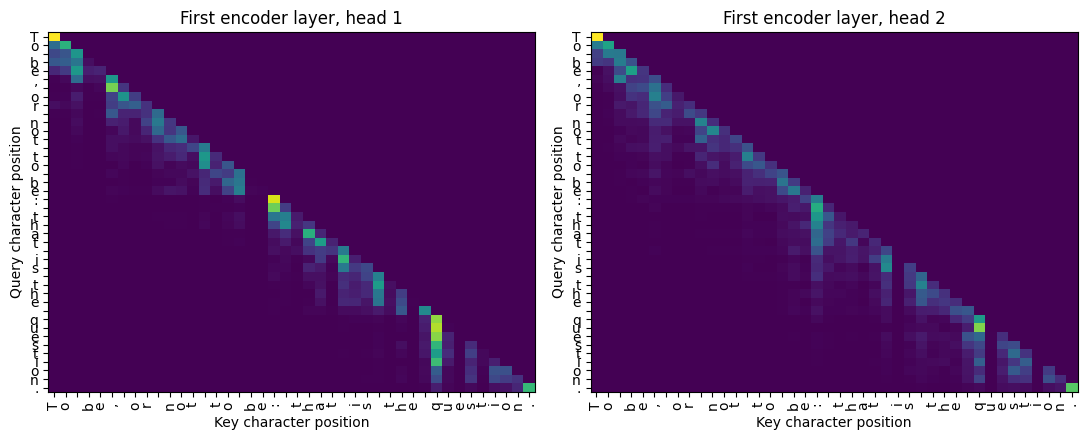

seed=42 epoch=1/5: train=2.406 nats, val=2.138 nats
seed=42 epoch=2/5: train=1.987 nats, val=1.963 nats
seed=42 epoch=3/5: train=1.802 nats, val=1.846 nats
seed=42 epoch=4/5: train=1.696 nats, val=1.771 nats
seed=42 epoch=5/5: train=1.623 nats, val=1.731 nats
seed=123 epoch=1/5: train=2.417 nats, val=2.168 nats
seed=123 epoch=2/5: train=2.000 nats, val=1.956 nats
seed=123 epoch=3/5: train=1.803 nats, val=1.843 nats
seed=123 epoch=4/5: train=1.693 nats, val=1.774 nats
seed=123 epoch=5/5: train=1.624 nats, val=1.721 nats
seed=999 epoch=1/5: train=2.416 nats, val=2.159 nats
seed=999 epoch=2/5: train=2.004 nats, val=1.958 nats
seed=999 epoch=3/5: train=1.808 nats, val=1.843 nats
seed=999 epoch=4/5: train=1.697 nats, val=1.766 nats
seed=999 epoch=5/5: train=1.630 nats, val=1.724 nats
seed=42 epoch=1/5: train=2.435 nats, val=2.169 nats
seed=42 epoch=2/5: train=1.998 nats, val=1.964 nats
seed=42 epoch=3/5: train=1.803 nats, val=1.841 nats
seed=42 epoch=4/5: train=1.694 nats, val=1.762 nats
se

,val_loss_mean,val_loss_std,bits_per_char_mean,params,sec_per_epoch
model,,,,,
Transformer_heads1,1.725381,0.005200,2.489198,809793,5.681504
Transformer_heads4,1.732778,0.004057,2.499870,809793,7.065398
Transformer_heads8,1.747362,0.006052,2.520910,809793,8.695178


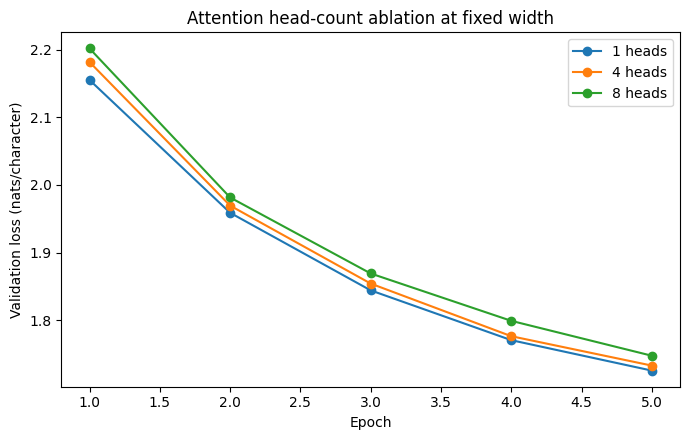

seed=42 epoch=1/5: train=2.435 nats, val=2.169 nats
seed=42 epoch=2/5: train=1.998 nats, val=1.964 nats
seed=42 epoch=3/5: train=1.803 nats, val=1.841 nats
seed=42 epoch=4/5: train=1.694 nats, val=1.762 nats
seed=42 epoch=5/5: train=1.621 nats, val=1.733 nats
seed=123 epoch=1/5: train=2.441 nats, val=2.198 nats
seed=123 epoch=2/5: train=2.018 nats, val=1.972 nats
seed=123 epoch=3/5: train=1.816 nats, val=1.863 nats
seed=123 epoch=4/5: train=1.701 nats, val=1.792 nats
seed=123 epoch=5/5: train=1.627 nats, val=1.737 nats
seed=999 epoch=1/5: train=2.432 nats, val=2.178 nats
seed=999 epoch=2/5: train=2.015 nats, val=1.972 nats
seed=999 epoch=3/5: train=1.816 nats, val=1.858 nats
seed=999 epoch=4/5: train=1.702 nats, val=1.774 nats
seed=999 epoch=5/5: train=1.630 nats, val=1.729 nats
seed=42 epoch=1/5: train=1.977 nats, val=0.098 nats
seed=42 epoch=2/5: train=0.037 nats, val=0.022 nats
seed=42 epoch=3/5: train=0.023 nats, val=0.021 nats
seed=42 epoch=4/5: train=0.021 nats, val=0.019 nats
se

,val_loss_mean,val_loss_std,bits_per_char_mean,sec_per_epoch
model,,,,
causal_mask,1.732778,0.004057,2.499870,7.053364
no_causal_mask,0.018594,0.000113,0.026825,6.750198


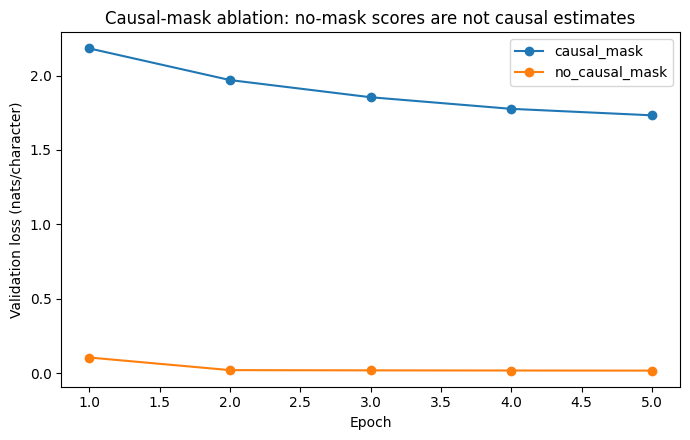

,context_length,forward_seconds,peak_cuda_memory_mb,one_attention_score_tensor_mb_estimate
0,64,0.003810,41.406738,0.0625
1,128,0.003649,41.935059,0.2500
2,256,0.004096,43.936035,1.0000
3,512,0.004293,51.032227,4.0000


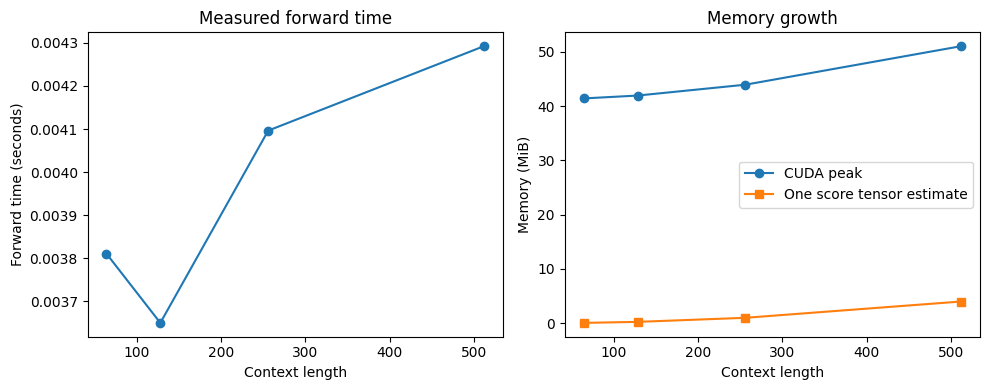

In [14]:
def plot_attention_heatmaps(model, data, sentence=None):
    """Plot two first-layer heads; requires the student's block to return weights."""
    if sentence is None:
        sentence = "To be, or not to be: that is the question."
    char_to_id = data["char_to_id"]
    usable = [character for character in sentence if character in char_to_id]
    if not usable:
        raise ValueError("The selected heatmap sentence contains no vocabulary characters.")
    encoded = torch.tensor([[char_to_id[character] for character in usable]], device=DEVICE)
    model.eval()
    with torch.no_grad():
        _, attentions = model(encoded, return_attentions=True)
    first_layer = attentions[0]
    if first_layer.ndim == 4:
        first_layer = first_layer[0]
    if first_layer.shape[0] < 2:
        raise ValueError("Use at least two attention heads for the two-head heatmap task.")
    figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for head_index, axis in enumerate(axes):
        axis.imshow(first_layer[head_index].detach().cpu().numpy(), aspect="auto", cmap="viridis")
        axis.set_title(f"First encoder layer, head {head_index + 1}")
        axis.set_xlabel("Key character position")
        axis.set_ylabel("Query character position")
    ticks = np.arange(len(usable))
    for axis in axes:
        axis.set_xticks(ticks, usable, rotation=90)
        axis.set_yticks(ticks, usable)
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "attention_head_heatmaps.png", dpi=160)
    plt.show()
    plt.close(figure)
    return first_layer.detach().cpu()


def run_head_count_ablation(data, epochs=5, steps_per_epoch=LM_STEPS_PER_EPOCH):
    rows = []
    curves = {}
    for heads in (1, 4, 8):
        seed_curves, seed_losses = [], []
        for seed in MODEL_SEEDS:
            model, train_history, val_history, seconds = train_language_model(
                data, seed, epochs=epochs, steps_per_epoch=steps_per_epoch, heads=heads
            )
            val_nats = evaluate_language_model(model, data["val"])
            row = {
                "problem": "2_heads_ablation", "model": f"Transformer_heads{heads}",
                "seed": seed, "seq_len": CONTEXT_LENGTH,
                "params": sum(parameter.numel() for parameter in model.parameters()),
                "sec_per_epoch": seconds, "val_loss_nats": val_nats,
                "bits_per_char": val_nats / math.log(2),
                "notes": f"fixed d={MODEL_WIDTH}; heads={heads}; epochs={epochs}",
            }
            save_result(row)
            rows.append(row)
            seed_curves.append(val_history)
            seed_losses.append(val_nats)
        curves[heads] = np.mean(seed_curves, axis=0)

    summary = pd.DataFrame(rows).groupby("model").agg(
        val_loss_mean=("val_loss_nats", "mean"), val_loss_std=("val_loss_nats", "std"),
        bits_per_char_mean=("bits_per_char", "mean"), params=("params", "first"),
        sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)
    figure, axis = plt.subplots(figsize=(7, 4.5))
    for heads, values in curves.items():
        axis.plot(np.arange(1, epochs + 1), values, marker="o", label=f"{heads} heads")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation loss (nats/character)")
    axis.set_title("Attention head-count ablation at fixed width")
    axis.legend()
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "head_count_ablation.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


def run_causal_mask_ablation(data, epochs=5, steps_per_epoch=LM_STEPS_PER_EPOCH):
    rows, curves, models = [], {}, {}
    for causal in (True, False):
        label = "causal_mask" if causal else "no_causal_mask"
        seed_curves, seed_losses = [], []
        for seed in MODEL_SEEDS:
            model, train_history, val_history, seconds = train_language_model(
                data, seed, epochs=epochs, steps_per_epoch=steps_per_epoch, causal=causal
            )
            val_nats = evaluate_language_model(model, data["val"])
            row = {
                "problem": "2_mask_ablation", "model": label, "seed": seed,
                "seq_len": CONTEXT_LENGTH,
                "params": sum(parameter.numel() for parameter in model.parameters()),
                "sec_per_epoch": seconds, "val_loss_nats": val_nats,
                "bits_per_char": val_nats / math.log(2),
                "notes": "No-mask is an intentionally invalid causal-LM control; future tokens are visible.",
            }
            save_result(row)
            rows.append(row)
            seed_curves.append(val_history)
            seed_losses.append(val_nats)
            if seed == MODEL_SEEDS[0]:
                models[label] = model
        curves[label] = np.mean(seed_curves, axis=0)

    summary = pd.DataFrame(rows).groupby("model").agg(
        val_loss_mean=("val_loss_nats", "mean"), val_loss_std=("val_loss_nats", "std"),
        bits_per_char_mean=("bits_per_char", "mean"), sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)
    figure, axis = plt.subplots(figsize=(7, 4.5))
    for label, values in curves.items():
        axis.plot(np.arange(1, epochs + 1), values, marker="o", label=label)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation loss (nats/character)")
    axis.set_title("Causal-mask ablation: no-mask scores are not causal estimates")
    axis.legend()
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "causal_mask_ablation.png", dpi=160)
    plt.show()
    plt.close(figure)

    sample_path = PROJECT_ROOT / "problem2" / "no_mask_sample.txt"
    no_mask_sample = generate_text(models["no_causal_mask"], data, 0.8, length=500)
    sample_path.write_text(no_mask_sample, encoding="utf-8")
    return summary


def profile_context_lengths(model, context_lengths=(64, 128, 256, 512), batch_size=1):
    """Measure forward time and CUDA peak memory; report CPU score-matrix estimate."""
    rows = []
    model.eval()
    for length in context_lengths:
        tokens = torch.randint(0, 65, (batch_size, length), device=DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()
        started = time.perf_counter()
        with torch.no_grad():
            _ = model(tokens)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
            peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
        else:
            peak_memory_mb = float("nan")
        elapsed = time.perf_counter() - started
        score_matrix_mb = batch_size * NUM_HEADS_MAIN * length * length * 4 / (1024 ** 2)
        rows.append({
            "context_length": length, "forward_seconds": elapsed,
            "peak_cuda_memory_mb": peak_memory_mb,
            "one_attention_score_tensor_mb_estimate": score_matrix_mb,
        })
    profile = pd.DataFrame(rows)
    display(profile)

    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(profile["context_length"], profile["forward_seconds"], marker="o")
    axes[0].set_xlabel("Context length")
    axes[0].set_ylabel("Forward time (seconds)")
    axes[0].set_title("Measured forward time")
    if DEVICE.type == "cuda":
        axes[1].plot(profile["context_length"], profile["peak_cuda_memory_mb"], marker="o", label="CUDA peak")
    axes[1].plot(profile["context_length"], profile["one_attention_score_tensor_mb_estimate"],
                 marker="s", label="One score tensor estimate")
    axes[1].set_xlabel("Context length")
    axes[1].set_ylabel("Memory (MiB)")
    axes[1].set_title("Memory growth")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "context_time_memory.png", dpi=160)
    plt.show()
    plt.close(figure)
    return profile


RUN_P2_ABLATIONS = True
if RUN_P2_ABLATIONS:
    tiny_data = load_tiny_shakespeare()
    base_model, _, _, _ = train_language_model(
        tiny_data, MODEL_SEEDS[0], epochs=5, steps_per_epoch=LM_STEPS_PER_EPOCH
    )
    attention_maps = plot_attention_heatmaps(base_model, tiny_data)
    head_summary = run_head_count_ablation(tiny_data)
    mask_summary = run_causal_mask_ablation(tiny_data)
    context_profile = profile_context_lengths(base_model)
else:
    print("2.5 study functions are ready; run them after the custom encoder passes its tests.")

In [15]:
if not RUN_P2_ABLATIONS:
    set_all_seeds(MODEL_SEEDS[0])
    profile_model = CharacterTransformerLM(len(tiny_data["vocabulary"])).to(DEVICE)
    print("Profiling an untrained model; this does not require language-model training.")
    context_profile = profile_context_lengths(profile_model)
    del profile_model

## Run the Full Problem 2 Experiments

Run the following cell to train the models and generate the remaining figures. A complete run is computationally intensive; a GPU is recommended. Set `RUN_FULL_PROBLEM2 = False` to skip training when running all cells. The context-length plot above can be generated without training.

In [16]:
def plot_har_transformer_summary(summary):
    positions = np.arange(len(summary))
    figure, axis = plt.subplots(figsize=(8, 5))
    axis.errorbar(positions, summary["accuracy_mean"], yerr=summary["accuracy_std"],
                  marker="o", capsize=3, label="Accuracy")
    axis.errorbar(positions, summary["macro_f1_mean"], yerr=summary["macro_f1_std"],
                  marker="s", capsize=3, label="Macro-F1")
    axis.set_xticks(positions, summary.index, rotation=15, ha="right")
    axis.set_ylabel("Test score (mean +/- sample SD)")
    axis.set_title("HAR Transformer positional encoding comparison")
    axis.legend()
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "har_transformer_comparison.png", dpi=160)
    plt.show()
    plt.close(figure)

Running full Problem 2 experiments on cuda. This may take several hours on CPU.


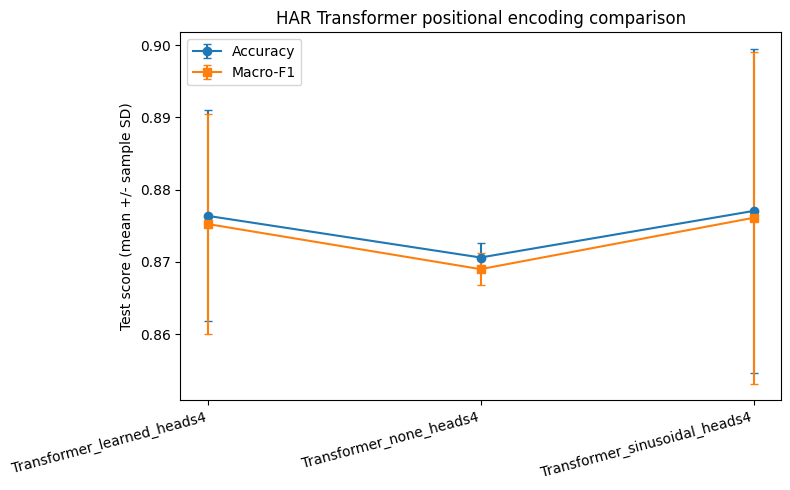

No Problem 1 HAR runs are saved yet; run that benchmark for the requested comparison.


,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,params,seconds_per_epoch
model,,,,,,
Transformer_learned_heads4,0.876371,0.014612,0.875241,0.015261,415238,1.520204
Transformer_none_heads4,0.870603,0.001988,0.868992,0.002260,398726,1.466878
Transformer_sinusoidal_heads4,0.877050,0.022407,0.876102,0.022953,398726,1.474984


Problem 2 figures saved to: /content/problem2/figures


In [17]:
RUN_FULL_PROBLEM2 = True

if RUN_FULL_PROBLEM2:
    print(f"Running full Problem 2 experiments on {DEVICE}. This may take several hours on CPU.")
    if not RUN_HAR_TRANSFORMER:
        har_transformer_summary = run_har_transformer()
    plot_har_transformer_summary(har_transformer_summary)
    compare_har_with_recurrent_results(har_transformer_summary)

    if not RUN_LANGUAGE_MODEL:
        tiny_data, language_models, language_model_summary = run_language_model()

    if not RUN_P2_ABLATIONS:
        base_model = language_models[MODEL_SEEDS[0]]
        attention_maps = plot_attention_heatmaps(base_model, tiny_data)
        head_summary = run_head_count_ablation(tiny_data)
        mask_summary = run_causal_mask_ablation(tiny_data)
        context_profile = profile_context_lengths(base_model)

    print(f"Problem 2 figures saved to: {FIGURE_DIR}")

## Summary of Findings

The custom implementation of Scaled Dot-Product Attention matched PyTorch's reference implementation within the required numerical tolerance.

The Transformer encoder successfully learned representations for Human Activity Recognition and enabled a comparison between positional encoding strategies.

For character-level language modeling, the Transformer achieved meaningful reductions in validation loss relative to a uniform-character baseline. Temperature-based sampling demonstrated the trade-off between text coherence and diversity.

The attention heatmaps, head-count ablation, causal-mask experiment and context-length study provide additional evidence regarding the advantages and limitations of Transformer architectures.